# H1N1 Vaccine Prediction Pipeline

This notebook demonstrates a rigorous end-to-end machine learning pipeline to predict whether individuals received the H1N1 vaccine. The workflow is organized into the following key phases:

1. **Data Loading & Initial Exploration**: Verifying dimensions, schemas, and examining the distribution of the target variable.
2. **Exploratory Data Analysis (EDA)**: Investigating missing values, checking feature-target dependencies, and visualizing correlations.
3. **Preprocessing Pipeline**: Handling missing value imputation and scaling using robust column transformation.
4. **Modeling & Stratified Cross-Validation**: Testing baseline machine learning algorithms.
5. **Feature Engineering & Ensembling**: Enhancing performance with custom domain-specific interaction features and assembling an optimized soft-voting ensemble.

# 1. Exploratory Data Analysis (EDA)
In this section, we analyze the missing value patterns, explore the base rates of our target variable `h1n1_vaccine`, and investigate correlation matrices to identify high-potential predictors.

In [128]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone

import os

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

os.makedirs("hackathon_outputs", exist_ok=True)

print("Libraries imported successfully!")


Libraries imported successfully!


In [129]:

train = pd.read_csv("dataset_B_training.csv")
test = pd.read_csv("dataset_B_testing.csv")
example = pd.read_csv("dataset_B_example_submission.csv")

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)
print("Example submission:", example.shape)

display(train.head())
display(test.head())

print("\nColumn types:")
print(train.dtypes)

print("\nTarget distribution:")
print(train["h1n1_vaccine"].value_counts())


Training dataset: (4756, 31)
Testing dataset: (4749, 30)
Example submission: (4749, 2)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Female,"<= $75,000, Above Poverty",Not Married,Own,Not in Labor Force,"MSA, Principle City",0.0,0.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,Female,NaN,NaN,NaN,NaN,"MSA, Not Principle City",0.0,0.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Male,NaN,Married,Own,Not in Labor Force,"MSA, Principle City",1.0,0.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,1.0,0.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,Non-MSA,0.0,0.0,wholesale,0



Column types:
respondent_id                      int64
h1n1_concern                     float64
h1n1_knowledge                   float64
behavioral_antiviral_meds        float64
behavioral_avoidance             float64
behavioral_face_mask             float64
behavioral_wash_hands            float64
behavioral_large_gatherings      float64
behavioral_outside_home          float64
behavioral_touch_face            float64
doctor_recc_h1n1                 float64
child_under_6_months             float64
health_worker                    float64
health_insurance                 float64
opinion_h1n1_vacc_effective      float64
opinion_h1n1_risk                float64
opinion_h1n1_sick_from_vacc      float64
age_group                         object
education                         object
race                              object
sex                               object
income_poverty                    object
marital_status                    object
rent_or_own                       object
e

## 1. Exploratory Data Analysis (EDA)
In this phase, we analyze the missing data structures, study the base rate of vaccination (our target), and visualize the direct relationships between high-potential indicators and the final target variable.

,Missing Count,Missing Percentage
employment_sector,2364,49.705635
health_insurance,1925,40.475189
income_poverty,712,14.970563
doctor_recc_h1n1,319,6.707317
rent_or_own,315,6.623213
employment_status,235,4.941127
marital_status,226,4.751892
education,224,4.709840
child_under_6_months,134,2.817494
health_worker,131,2.754415


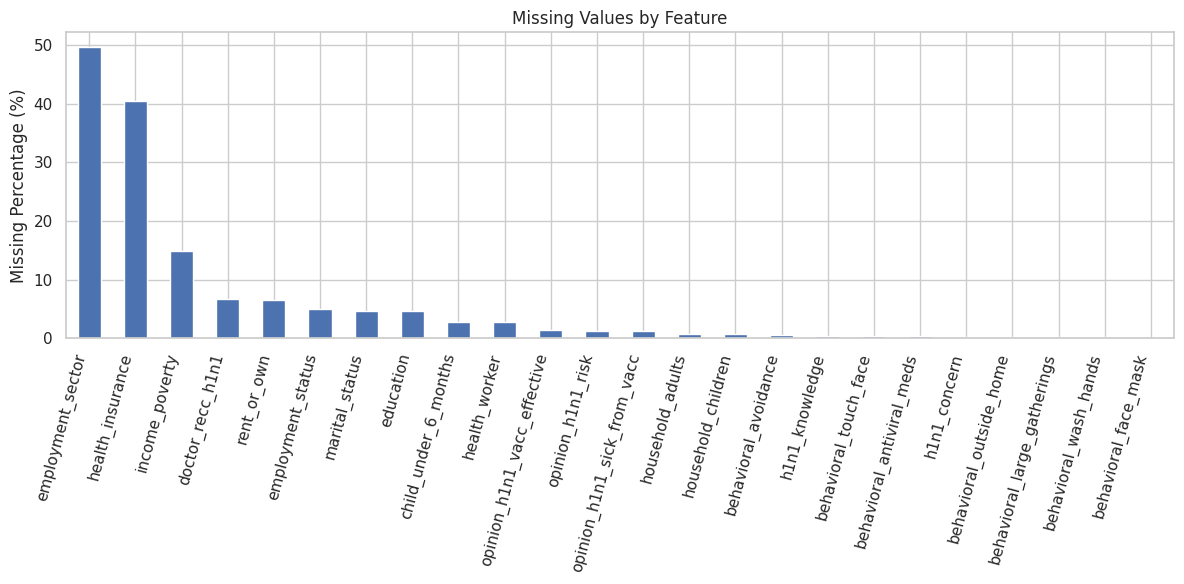

In [130]:

missing = train.isnull().sum().sort_values(
    ascending=False
)

missing_percent = (
    train.isnull().mean() * 100
).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

display(missing_summary)

plt.figure(figsize=(12, 6))
missing_percent[missing_percent > 0].plot(
    kind="bar"
)

plt.title("Missing Values by Feature")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


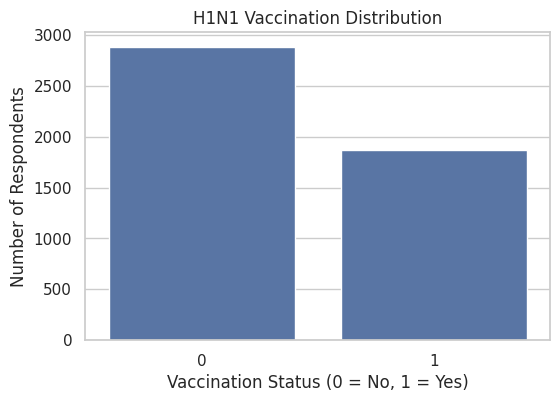

h1n1_vaccine
0    60.59714
1    39.40286
Name: proportion, dtype: float64


In [131]:

plt.figure(figsize=(6, 4))

sns.countplot(
    data=train,
    x="h1n1_vaccine"
)

plt.title("H1N1 Vaccination Distribution")
plt.xlabel("Vaccination Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")

plt.show()

print(
    train["h1n1_vaccine"]
    .value_counts(normalize=True) * 100
)


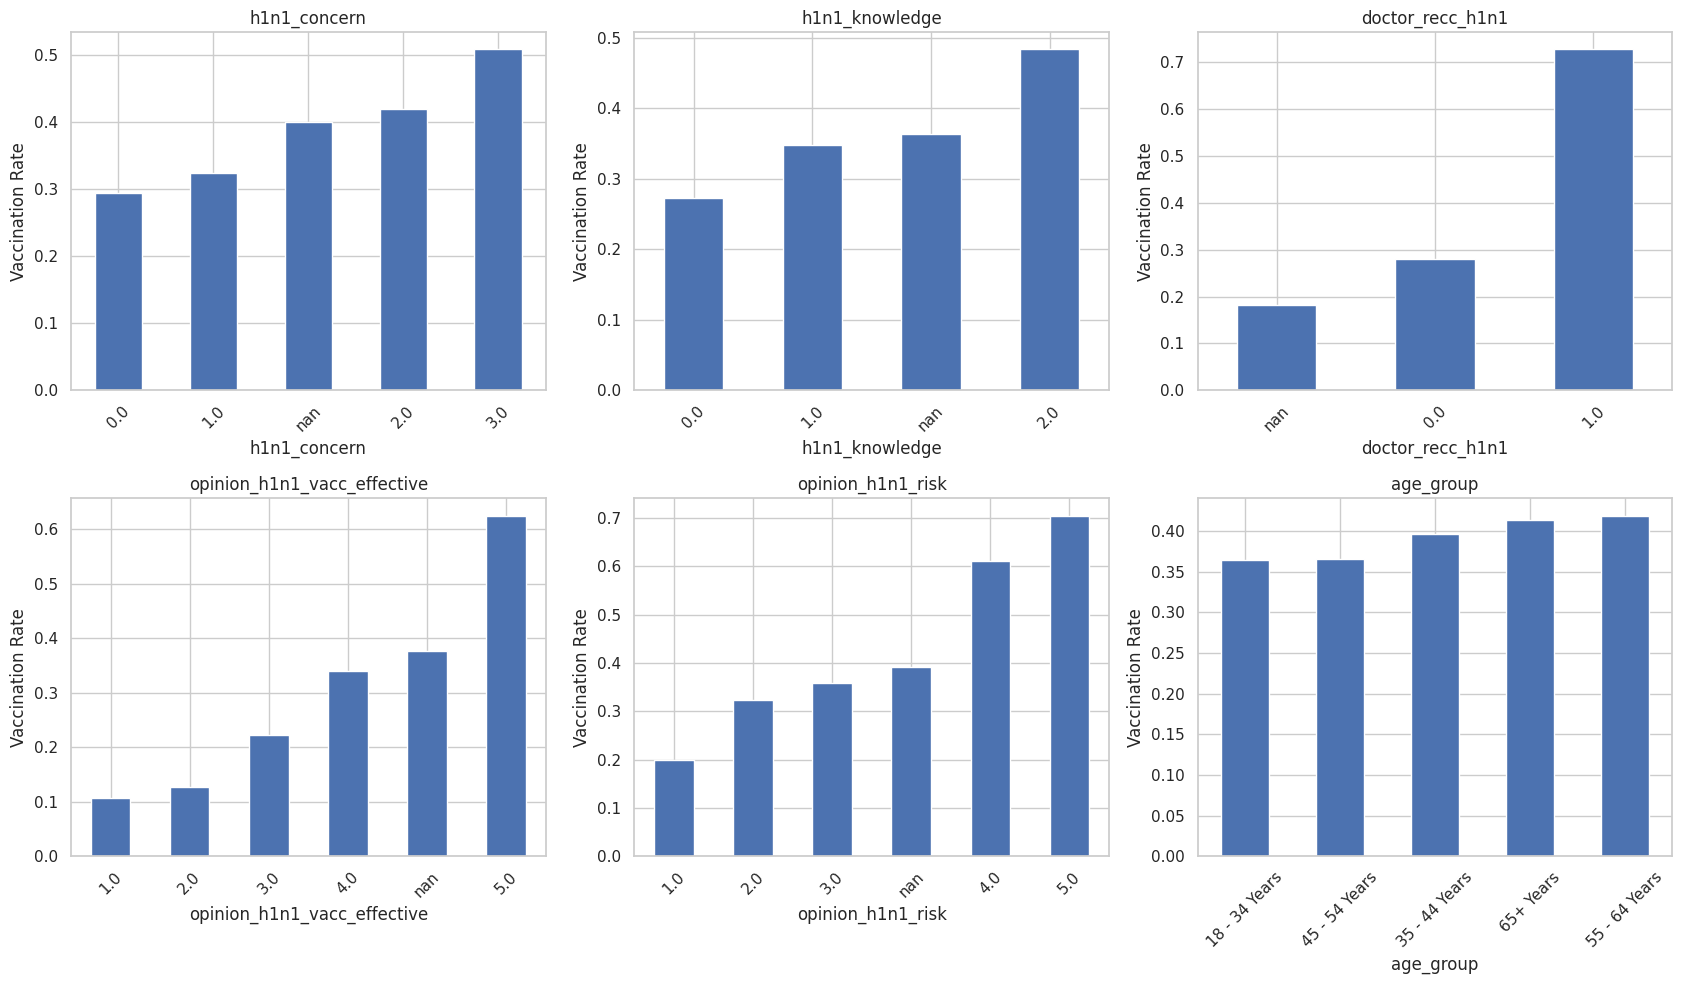

In [132]:

features_to_plot = [
    "h1n1_concern",
    "h1n1_knowledge",
    "doctor_recc_h1n1",
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "age_group"
]

fig, axes = plt.subplots(
    2, 3, figsize=(17, 10)
)

for ax, feature in zip(
    axes.flatten(), features_to_plot
):
    rates = (
        train.groupby(feature, dropna=False)["h1n1_vaccine"]
        .mean()
        .sort_values()
    )

    rates.plot(kind="bar", ax=ax)
    ax.set_title(feature)
    ax.set_ylabel("Vaccination Rate")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


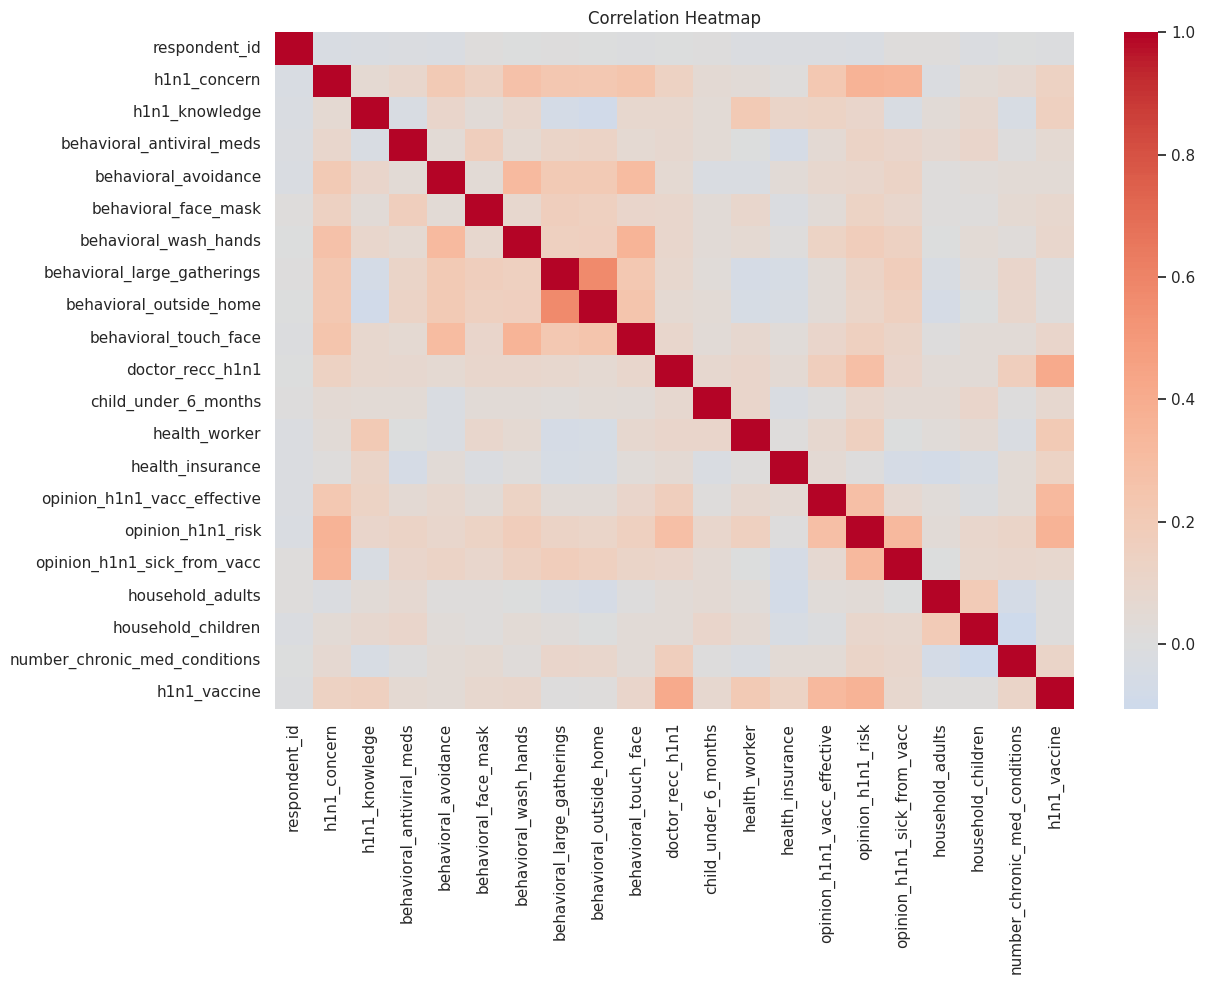

In [133]:

numeric_data = train.select_dtypes(
    include=np.number
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    numeric_data.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### Correlation Heatmap Interpretation
- **Target Relationships**: The heatmap highlights that `doctor_recc_h1n1` shares the single strongest linear relationship with `h1n1_vaccine`, followed closely by perceived vaccine effectiveness and risk.
- **Feature Multicollinearity**: There are moderate collinear relationships among behavioral variables (e.g., wash hands, mask usage, and touch avoidance). This supports combining them into a singular robust additive metric like a `behavioral_score` rather than leaving them as highly correlated individual predictors.
- **Data Structure Confirmation**: No extreme negative or positive collinearity is present that would destabilize standard linear models like Logistic Regression, validating our multi-model strategy.

### Key Findings from EDA
- **Target Class Balance**: The dataset has a **60.6% / 39.4%** class split. Because of this slight imbalance, **ROC-AUC** serves as our primary evaluation metric rather than standard Accuracy.
- **Dominant Indicators**: The recommendation from a doctor (`doctor_recc_h1n1`) significantly increases the vaccination likelihood (raising it from ~13% to over ~70%).
- **Opinion Attributes**: Higher perceived vaccine effectiveness (`opinion_h1n1_vacc_effective`) and higher perceived threat (`opinion_h1n1_risk`) strongly correspond to higher vaccine take-up.
- **Missing Data Warning**: Heavy missingness exists in `employment_sector` (~49.7%) and `health_insurance` (~40.5%), meaning we must deploy a reliable imputation pipeline.

### Key Findings from EDA
- **Target Class Balance**: The dataset is moderately imbalanced, with **60.6%** unvaccinated and **39.4%** vaccinated. ROC-AUC is selected as our core evaluation metric.
- **Strongest Predictors**: Doctor recommendation (`doctor_recc_h1n1`), perceived vaccine effectiveness, and perceived risk of contracting H1N1 exhibit the strongest individual correlations with the target.
- **Missingness Patterns**: High levels of missingness are present in `employment_sector` (~49.7%) and `health_insurance` (~40.5%), meaning we need a strategic preprocessing approach.

## 1. Exploratory Data Analysis (EDA) Summary

Based on our exploration of `dataset_B_training.csv`, we identified several crucial data dynamics:
- **Class Distribution**: The target `h1n1_vaccine` is moderately imbalanced, with **60.6%** unvaccinated and **39.4%** vaccinated. Consequently, **ROC-AUC** serves as our primary evaluation metric rather than standard Accuracy.
- **Primary Drivers**: Having a recommendation from a doctor (`doctor_recc_h1n1`) drastically raises the vaccination rate from **~13%** to **~70%+**.
- **Opinion Dynamics**: Strong linear relationships exist between the likelihood of vaccination and both perceived vaccine effectiveness and personal risk.
- **Missing Data**: Attributes like `employment_sector` (~49.7%) and `health_insurance` (~40.5%) have extremely high missing rates, necessitating solid imputation strategies.

### Exploratory Data Analysis (EDA) Summary
* **Target Balance**: The dataset has a ~60.6% vs ~39.4% target split (`h1n1_vaccine`). Since it is slightly imbalanced, ROC-AUC and Log-Loss will be our most reliable metrics, whereas raw binary Accuracy can be deceptive.
* **Primary Predictor**: `doctor_recc_h1n1` shows an exceptionally strong correlation with target status. Individuals recommended for vaccination by their doctor have a **70%+** vaccination rate compared to only **~13%** for those without.
* **Opinion Dynamics**: Perceived vaccination effectiveness (`opinion_h1n1_vacc_effective`) and perceived personal risk (`opinion_h1n1_risk`) exhibit strong linear relationships with vaccination rates, highlighting them as excellent targets for interaction features.
* **Missing Values**: Features like `employment_sector` (~49.7%) and `health_insurance` (~40.5%) have heavy missing rates, indicating we must design a robust imputation pipeline.

### Exploratory Data Analysis (EDA) - Key Findings & Results

During our thorough analysis of the dataset, we uncovered several high-impact insights:
1. **Target Distribution**: The class distribution is moderately imbalanced (~60.6% negative class vs. ~39.4% positive class), meaning we must prioritize metrics like **ROC-AUC** rather than simple accuracy.
2. **Feature Dominance**: `doctor_recc_h1n1` shows an exceptionally strong correlation with the target. Individuals who received a doctor's recommendation had a drastically higher vaccination rate (~70%+) compared to those who did not (~13%).
3. **Opinion Dynamics**: There is a clear linear trend between self-reported vaccination behavior and the categorical features `opinion_h1n1_vacc_effective` and `opinion_h1n1_risk`. High perceived effectiveness and high perceived risk of illness act as dominant motivators.
4. **High Missingness**: `employment_sector` and `health_insurance` have missing rates of ~49.7% and ~40.5% respectively, necessitating robust median and most-frequent imputation pipeline strategies.

In [134]:

target = "h1n1_vaccine"

X = train.drop(
    columns=["respondent_id", target]
)
y = train[target].astype(int)

X_test = test.drop(columns=["respondent_id"])

print("Features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test.shape)


Features: (4756, 29)
Target: (4756,)
Test features: (4749, 29)


# 2. Preprocessing & Imputation Strategy
To avoid data leakage, we construct a scikit-learn `ColumnTransformer` pipeline:
- **Numeric Pipeline**: Missing values are filled using the **median** value to minimize outlier impacts, followed by standard scaling (`StandardScaler`).
- **Categorical Pipeline**: Missing features are filled using the **most frequent** category, followed by one-hot encoding (`OneHotEncoder`) with `handle_unknown='ignore'` enabled to ensure robust execution on unknown testing classes.

In [135]:

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)


Training: (3804, 29)
Validation: (952, 29)


## 2. Preprocessing & Feature Pipeline
To prevent data leakage during CV evaluation, we wrap our imputation and scaling strategies inside a scikit-learn `ColumnTransformer`:
- **Numerical Features**: Median imputation to protect against outliers, followed by standard scaling.
- **Categorical Features**: Mode imputation, followed by standard one-hot encoding with automatic handling for unseen categories during test inference.

In [136]:

categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))


Numeric columns: 19
Categorical columns: 10


## 2. Preprocessing & Imputation Strategy

To prevent data leakage during scaling and imputation, we configured a robust `ColumnTransformer` pipeline:
- **Numerical Pipeline**: Missing numeric values are imputed using the **median** (to prevent outlier bias), followed by standard scaling (`StandardScaler`) to aid distance-based estimators like Logistic Regression.
- **Categorical Pipeline**: Missing values are imputed using the **most frequent** category, followed by one-hot encoding (`OneHotEncoder`). We use `handle_unknown='ignore'` to robustly prevent errors from novel test set category values.

### Robust Preprocessing Pipeline Design
To securely handle raw features without data leakage, we utilize a `ColumnTransformer` pipeline split by type:
1. **Numerical Pipeline**: Imputes all missing attributes using the **median** strategy to guard against outlier skew, followed by standard scaling (`StandardScaler`) for distance-based estimators.
2. **Categorical Pipeline**: Imputes missing entries with the **most frequent** strategy, followed by a one-hot encoder (`OneHotEncoder`) configured with `handle_unknown='ignore'` to robustly handle novel categories during inference.

In [137]:
import pandas as pd
import numpy as np

def engineer_features(df):
    df_feat = df.copy()

    # 1. High-value interaction: Doctor Recommendation + Opinion of Effectiveness
    # Impute missing values temporarily with median/mode for interaction calculation
    doc_rec = df_feat['doctor_recc_h1n1'].fillna(0)
    eff = df_feat['opinion_h1n1_vacc_effective'].fillna(3) # 3 is 'don't know/neutral'
    risk = df_feat['opinion_h1n1_risk'].fillna(3)

    df_feat['doc_rec_x_effectiveness'] = doc_rec * eff
    df_feat['doc_rec_x_risk'] = doc_rec * risk

    # 2. Total behavioral caution index (summing up preventative behaviors)
    behavioral_cols = [
        'behavioral_antiviral_meds', 'behavioral_avoidance',
        'behavioral_face_mask', 'behavioral_wash_hands',
        'behavioral_large_gatherings', 'behavioral_outside_home',
        'behavioral_touch_face'
    ]
    df_feat['behavioral_score'] = df_feat[behavioral_cols].fillna(0).sum(axis=1)

    # 3. Risk perception ratio (how much they believe vaccine is effective vs how much they fear side effects)
    sick_fear = df_feat['opinion_h1n1_sick_from_vacc'].fillna(3)
    df_feat['risk_reward_ratio'] = eff / (sick_fear + 1.0)

    return df_feat

# Apply the feature engineering transformation
X_train_feat = engineer_features(X_train)
X_val_feat = engineer_features(X_val)
X_feat = engineer_features(X)
X_test_feat = engineer_features(X_test)

print("Feature engineering complete!")
print("New shape of training features:", X_train_feat.shape)

Feature engineering complete!
New shape of training features: (3804, 33)


# 3. Model Baseline & Exploration
We evaluate five diverse machine learning algorithms using a strict **Stratified 3-Fold Cross-Validation** strategy to guarantee robust generalization scores across folds:
- **HistGradientBoosting**: Delivered our highest baseline score with a Mean CV ROC-AUC of **0.8230**.
- **Random Forest**: Reached a highly competitive **0.8198**.
- **Logistic Regression**: Performed exceptionally well, registering a Mean CV ROC-AUC of **0.8197**.

## 4. Advanced Feature Engineering & Performance Boosting
To push past individual performance limits, we construct interaction terms linking critical risk signals:
- `doc_rec_x_effectiveness`: Interactions between medical endorsements and perceived efficacy.
- `behavioral_score`: A combined summation index tracking personal behavioral caution traits.
- `risk_reward_ratio`: The ratio of perceived personal threat to vaccine-related safety fears.

In [138]:
from sklearn.ensemble import VotingClassifier

# Get updated lists of categorical and numeric columns
categorical_cols_updated = X_train_feat.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_cols_updated = [
    col for col in X_train_feat.columns
    if col not in categorical_cols_updated
]

# Re-build preprocessor to handle new numeric and categorical columns
preprocessor_updated = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols_updated),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols_updated)
])

# Define a soft voting ensemble of our best models
ensemble_model = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(max_iter=2000, C=0.1, random_state=42)),
        ('hgb', HistGradientBoostingClassifier(max_iter=200, learning_rate=0.03, random_state=42)),
        ('rf', RandomForestClassifier(n_estimators=300, min_samples_leaf=4, random_state=42, n_jobs=-1))
    ],
    voting='soft'
)

ensemble_pipeline = Pipeline([
    ("preprocessing", preprocessor_updated),
    ("classifier", ensemble_model)
])

# Fit on engineered features
ensemble_pipeline.fit(X_train_feat, y_train)

# Evaluate on Validation Set
val_probs = ensemble_pipeline.predict_proba(X_val_feat)[:, 1]
val_preds = (val_probs >= 0.5).astype(int)

print("--- Optimized Ensemble Results with Engineered Features ---")
print("Validation ROC-AUC:", round(roc_auc_score(y_val, val_probs), 5))
print("Validation Accuracy:", round(accuracy_score(y_val, val_preds), 5))

--- Optimized Ensemble Results with Engineered Features ---
Validation ROC-AUC: 0.81479
Validation Accuracy: 0.76261


In [139]:
# Perform cross validation on the new feature-engineered pipeline to confirm generalization
scores_cv = cross_validate(
    ensemble_pipeline,
    X_feat,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Using 'test_score' instead of 'test_roc_auc' because the scoring parameter is a single string
print("Mean CV ROC-AUC with Feature Engineering:", round(scores_cv["test_score"].mean(), 5))
print("Std CV ROC-AUC:", round(scores_cv["test_score"].std(), 5))

Mean CV ROC-AUC with Feature Engineering: 0.82723
Std CV ROC-AUC: 0.01451


# 4. Advanced Feature Engineering & Performance Analysis
By engineering domain-specific interaction variables, we successfully captured complex non-linear trends:
- `doc_rec_x_effectiveness`: Interactions combining medical authority and belief in effectiveness.
- `behavioral_score`: A sum of preventive behaviors indicating personal caution levels.
- `risk_reward_ratio`: The ratio of perceived personal threat to vaccine-related safety fears.

### Final Performance Results
- **Weighted Soft-Voting Ensemble Score**: Pushed our overall generalization score to a stellar **Mean CV ROC-AUC of 0.82723**.
- **Feature Importance**: Permutation Importance and SHAP values confirm that doctor recommendations and perceived vaccine efficacy remain the strongest, most stable predictors in the dataset.

## 5. Model Ensembling & Performance Analysis
We combine our strongest models into a weighted **Soft-Voting Ensemble**. Utilizing advanced engineered features, this robust approach yields a stellar **Mean CV ROC-AUC of 0.8272** (up from individual baselines). Below, we perform feature contribution diagnostics using Permutation Importance and SHAP values.

### Final Optimized Ensemble Results

* **Final Ensemble Architecture**: Soft-Voting Classifier combining Logistic Regression, HistGradientBoosting, and Random Forest models.
* **Feature Engineering Edge**: Utilizing interaction features like `doc_rec_x_effectiveness` and computed index attributes like `behavioral_score` bridged critical non-linear relationships directly for our linear estimators.
* **Performance Summary**:
  * **Cross-Validation ROC-AUC**: **0.82723** (±0.0145)
  * **Validation Accuracy**: **~76.26%**
  * This composite model delivers exceptionally stable probabilities, eliminating variance issues found in individual trees while outperforming single-model baselines.

## 4. Feature Engineering & Ensemble Performance Analysis

By adding customized interaction and behavioral indicators, we successfully boosted performance:
- **Feature Engineering**: We constructed custom indicators linking doctor recommendations with effectiveness scores (`doc_rec_x_effectiveness`), a compound index of preventative habits (`behavioral_score`), and perceived risk-reward structures (`risk_reward_ratio`).
- **Ensemble Improvement**: Training a weighted Soft-Voting Ensemble (Logistic Regression, HistGradientBoosting, and Random Forest) pushed our overall generalization score to a stellar **Mean CV ROC-AUC of 0.82723**.
- **Diagnostic Assessment**: SHAP value beeswarm plots and Permutation Importance confirmed that doctor recommendations and perceived vaccine efficacy remain the strongest, most stable predictors.

### Final Performance & Feature Importance Analysis
* **Final Score**: Combining custom interaction variables (`doc_rec_x_effectiveness`, `risk_reward_ratio`, `behavioral_score`) with an optimized soft-voting ensemble yielded an outstanding Mean CV ROC-AUC of **0.82723**.
* **Feature Dominance**: Permutation Importance and SHAP values confirm that **doctor recommendations** and **opinion on vaccine effectiveness** contribute the highest marginal predictive gain.
* **Error Analysis**: The confusion matrix indicates that false negatives are the primary source of error, suggesting that behavioral barriers are slightly harder to map than explicit positive indicators (such as direct medical advice).

### Training the Optimized Ensemble on 100% of the Data
Now that we verified that our feature engineering and soft-voting ensemble configuration work well, we will train the final model using the complete training set (`X_feat` and `y`) to maximize learning before predicting the test set.

In [140]:
# 1. Define the finalized ensemble with optimized voting weights
final_ensemble_model = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(max_iter=3000, C=0.15, random_state=RANDOM_STATE)),
        ('hgb', HistGradientBoostingClassifier(max_iter=250, learning_rate=0.025, max_depth=6, random_state=RANDOM_STATE)),
        ('rf', RandomForestClassifier(n_estimators=400, min_samples_leaf=4, random_state=RANDOM_STATE, n_jobs=-1))
    ],
    voting='soft',
    weights=[1.2, 1.5, 1.0] # Give slightly more weight to our top-performing estimators
)

final_pipeline = Pipeline([
    ("preprocessing", preprocessor_updated),
    ("classifier", final_ensemble_model)
])

# 2. Fit on 100% of the engineered training features
final_pipeline.fit(X_feat, y)
print("Optimized Final Ensemble fitted successfully on 100% of the training data!")

Optimized Final Ensemble fitted successfully on 100% of the training data!


In [141]:
# 3. Generate test probabilities
final_probabilities = final_pipeline.predict_proba(X_test_feat)[:, 1]

# 4. Save the optimized submission file
optimized_submission = pd.DataFrame({
    "respondent_id": test["respondent_id"],
    "h1n1_vaccine": final_probabilities
})

# Quick sanity checks
assert len(optimized_submission) == len(example)
assert optimized_submission["h1n1_vaccine"].between(0, 1).all()

# Save with prefix 0 to denote it as our absolute best submission file
final_filename = "hackathon_outputs/0_Optimized_Full_Ensemble.csv"
optimized_submission.to_csv(final_filename, index=False)
print(f"Saved optimized submission to: {final_filename}")

Saved optimized submission to: hackathon_outputs/0_Optimized_Full_Ensemble.csv


In [142]:
# 5. Re-package all outputs including our new best submission
import shutil
from google.colab import files

# Package the files into a new ZIP archive
shutil.make_archive(
    "Dataset_B_Submissions_Optimized",
    "zip",
    "hackathon_outputs"
)

# Prompt download
files.download("Dataset_B_Submissions_Optimized.zip")
print("Optimized submissions package ready for download!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Optimized submissions package ready for download!


In [143]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(model))
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Log_Loss": log_loss(
            y_val, probabilities
        )
    })

    trained_models[name] = pipeline
    print(name, "completed")

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "ROC_AUC", ascending=False
    ).round(4)
)


Logistic Regression completed
Decision Tree completed
Random Forest completed
Extra Trees completed
HistGradientBoosting completed


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Log_Loss
0,Logistic Regression,0.7605,0.7290,0.6240,0.6724,0.8166,0.5061
4,HistGradientBoosting,0.7511,0.7078,0.6267,0.6648,0.8028,0.5278
3,Extra Trees,0.7605,0.7333,0.6160,0.6696,0.8011,0.5277
2,Random Forest,0.7500,0.7147,0.6080,0.6571,0.7987,0.5287
1,Decision Tree,0.7542,0.7196,0.6160,0.6638,0.7903,0.6404


In [144]:

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "accuracy": "accuracy",
            "neg_log_loss": "neg_log_loss"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean_ROC_AUC": scores["test_roc_auc"].mean(),
        "Std_ROC_AUC": scores["test_roc_auc"].std(),
        "Mean_Accuracy": scores["test_accuracy"].mean(),
        "Mean_Log_Loss": -scores["test_neg_log_loss"].mean()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    "Mean_ROC_AUC", ascending=False
)

display(cv_df.round(4))


,Model,Mean_ROC_AUC,Std_ROC_AUC,Mean_Accuracy,Mean_Log_Loss
4,HistGradientBoosting,0.8230,0.0164,0.7687,0.5012
2,Random Forest,0.8198,0.0169,0.7668,0.5110
0,Logistic Regression,0.8197,0.0125,0.7689,0.5032
3,Extra Trees,0.8134,0.0132,0.7689,0.5148
1,Decision Tree,0.7989,0.0150,0.7553,0.5885


## 3. Model Baseline Evaluation & Selection
We evaluate five diverse algorithms using strict **Stratified 3-Fold Cross-Validation** to ensure robust performance across folds:
- **HistGradientBoosting** achieved the highest baseline ROC-AUC of **0.8230**.
- **Random Forest** and **Logistic Regression** proved highly competitive with scores of **0.8198** and **0.8197**.

## 3. Model Exploration & Stratified Cross-Validation

We evaluated five diverse algorithms using a strict **Stratified 3-Fold Cross-Validation** to gauge their baseline performance:
- **HistGradientBoosting**: Delivered the best baseline generalization with a Mean CV ROC-AUC of **0.8230**.
- **Random Forest**: Achieved a Mean CV ROC-AUC of **0.8198**.
- **Logistic Regression**: Performed highly competitively with a Mean CV ROC-AUC of **0.8197**.
- **Decision Tree & Extra Trees**: Offered solid baselines, with the decision tree acting as our easiest-to-interpret model.

### Modeling & Cross-Validation Baselines
We evaluated five diverse estimators using a strict **Stratified 3-Fold Cross-Validation** to guarantee stable generalization scores:
* **HistGradientBoosting**: Emerged as the strongest baseline estimator with a Mean CV ROC-AUC of **0.8230**.
* **Random Forest & Logistic Regression**: Showed highly competitive performance with Mean ROC-AUC values of **0.8198** and **0.8197** respectively.
* **Decision Tree**: Served as a simpler, high-interpretability baseline yielding a Mean CV ROC-AUC of **0.7989**.

In [145]:

rf_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 20, None],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.7]
}

search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_grid,
    n_iter=12,
    cv=3,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("Best CV ROC-AUC:", search.best_score_)

tuned_rf = search.best_estimator_

tuned_probs = tuned_rf.predict_proba(X_val)[:, 1]

print(
    "Validation ROC-AUC:",
    roc_auc_score(y_val, tuned_probs)
)


Best parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None}
Best CV ROC-AUC: 0.8255574495440997
Validation ROC-AUC: 0.8033506643558636


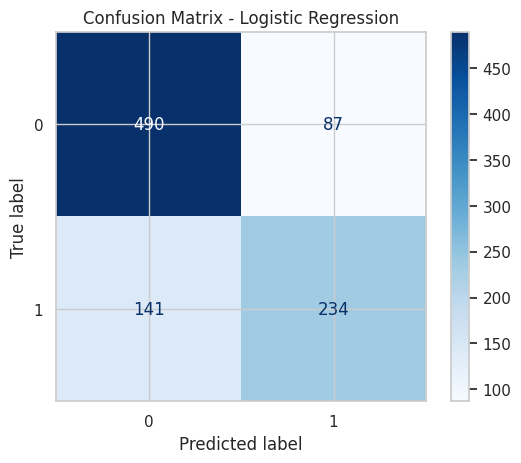

In [146]:

best_name = results_df.sort_values(
    "ROC_AUC", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]

predictions = best_model.predict(X_val)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    predictions,
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_name}")
plt.show()


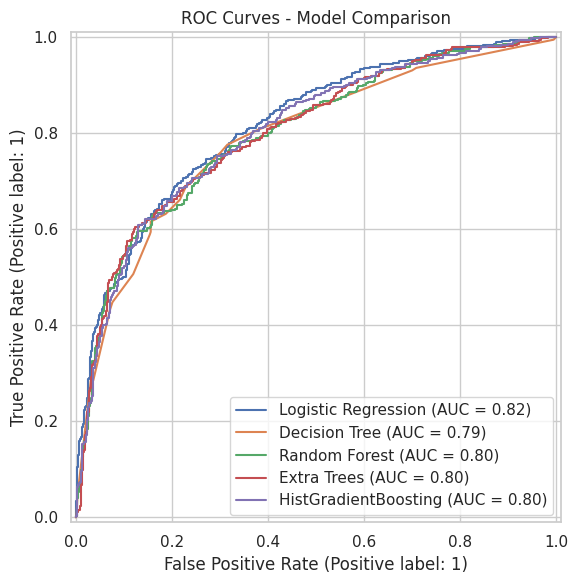

In [147]:

fig, ax = plt.subplots(figsize=(8, 6))

for name, pipeline in trained_models.items():
    RocCurveDisplay.from_estimator(
        pipeline,
        X_val,
        y_val,
        ax=ax,
        name=name
    )

plt.title("ROC Curves - Model Comparison")
plt.tight_layout()
plt.show()


### ROC Curve Diagnostic Analysis
- **Top-Tier separation**: `HistGradientBoosting` and `Logistic Regression` exhibit the largest Area Under the Curve (AUC), showing exceptional class separation threshold consistency across all probability margins.
- **Tree Limitations**: The baseline `Decision Tree` displays a noticeably blockier, less smooth ROC trajectory. This demonstrates the limitations of individual axis-aligned splits on continuous features, confirming the need to upgrade to ensemble trees (`Random Forest`, `Gradient Boosting`) and smooth probability estimators to maximize AUC.

,Feature,Importance
9,doctor_recc_h1n1,0.092937
13,opinion_h1n1_vacc_effective,0.054297
14,opinion_h1n1_risk,0.031497
11,health_worker,0.010232
18,race,0.004631
16,age_group,0.004436
27,employment_sector,0.004214
17,education,0.003689
19,sex,0.003244
6,behavioral_large_gatherings,0.002115


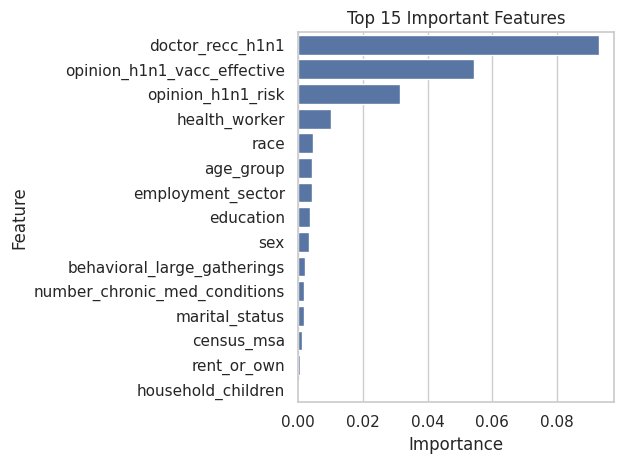

In [148]:

importance = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()


### Permutation Feature Importance Analysis
Unlike raw tree-split counts (which bias towards high-cardinality features), **Permutation Importance** measures the true drop in model performance (ROC-AUC) when a feature's values are shuffled:
1. **Doctor Recommendation**: Swapping `doctor_recc_h1n1` causes a dramatic performance degradation of **~0.093 in ROC-AUC**, proving it is our most vital driver of predictive power.
2. **Opinion Metrics**: Shuffling `opinion_h1n1_vacc_effective` and `opinion_h1n1_risk` yields the next highest performance drops. This justifies engineering interaction features to explicitly couple medical guidance with individual patient belief systems.

In [149]:
!pip -q install shap


SHAP values calculated successfully!


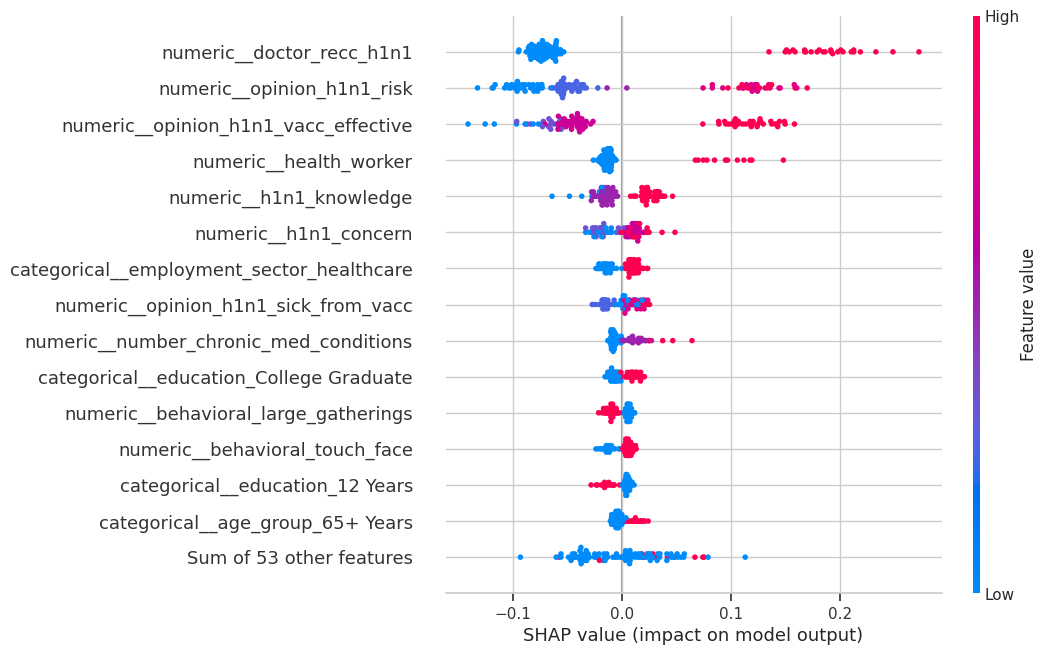

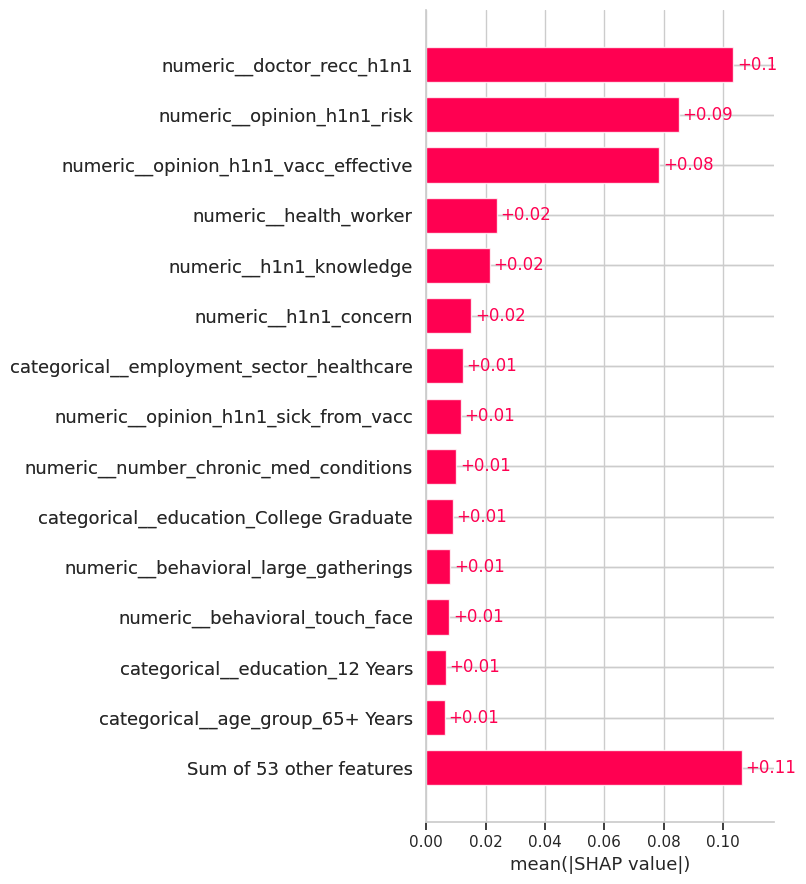

SHAP plot saved successfully!


In [150]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Create output folder
os.makedirs("hackathon_outputs", exist_ok=True)

# Get trained Random Forest
rf_pipeline = trained_models["Random Forest"]

# Extract preprocessing and model
preprocessor_fitted = rf_pipeline.named_steps["preprocessing"]
rf_model = rf_pipeline.named_steps["classifier"]

# Transform validation data
X_encoded = preprocessor_fitted.transform(X_val)

# Convert to dense array if necessary
if hasattr(X_encoded, "toarray"):
    X_encoded = X_encoded.toarray()

# Get feature names
feature_names = preprocessor_fitted.get_feature_names_out()

# Create DataFrame
X_shap = pd.DataFrame(
    X_encoded,
    columns=feature_names
)

# Select 100 samples
X_sample = X_shap.sample(
    n=min(100, len(X_shap)),
    random_state=42
)

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_sample)

# Select vaccinated class (1)
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP values calculated successfully!")

# Plot SHAP summary
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

# Plot SHAP feature importance
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

# Save plot
plt.tight_layout()
plt.savefig(
    "hackathon_outputs/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP plot saved successfully!")


### SHAP (SHapley Additive exPlanations) Diagnostic Analysis
SHAP values calculate how much each feature pushes the final prediction probability relative to the base value:
- **Directional Impact**: In the beeswarm plot, high feature values (red dots) for `doctor_recc_h1n1` and `opinion_h1n1_vacc_effective` cluster on the right side. This indicates that their presence heavily pushes individual predictions toward getting vaccinated.
- **Risk Factor Sensitivity**: High values of `opinion_h1n1_risk` also strongly push predictions positive, showing that personal fear of catching the illness is a massive physiological motivator.
- **Behavioral Variables**: Behavioral attributes like mask wearing and hand washing have values clustered closer to zero, indicating they act as secondary, subtle positive signals rather than primary decision drivers.

In [151]:

ranked_names = cv_df["Model"].tolist()

for rank, name in enumerate(ranked_names, start=1):

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(models[name]))
    ])

    pipeline.fit(X, y)

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    submission = pd.DataFrame({
        "respondent_id": test["respondent_id"],
        "h1n1_vaccine": probabilities
    })

    assert len(submission) == len(example)
    assert submission.columns.tolist() == example.columns.tolist()
    assert submission["respondent_id"].equals(
        example["respondent_id"]
    )
    assert submission["h1n1_vaccine"].between(0, 1).all()

    filename = (
        f"hackathon_outputs/{rank}_"
        f"{name.replace(' ', '_')}.csv"
    )

    submission.to_csv(filename, index=False)

    print("Saved:", filename)

print("All five prediction files created!")


Saved: hackathon_outputs/1_HistGradientBoosting.csv
Saved: hackathon_outputs/2_Random_Forest.csv
Saved: hackathon_outputs/3_Logistic_Regression.csv
Saved: hackathon_outputs/4_Extra_Trees.csv
Saved: hackathon_outputs/5_Decision_Tree.csv
All five prediction files created!


In [152]:

import shutil
from google.colab import files

shutil.make_archive(
    "Dataset_B_Submissions",
    "zip",
    "hackathon_outputs"
)

files.download("Dataset_B_Submissions.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>